In [1]:
import json

import hydroeval as he
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rain2loss.calibration import calibrate, glue_bounds, glue_sample
from rain2loss.hbv import PARAMS, PARAM_NAMES, elevation_zones, run_hbv
from rain2loss.lamah import load_attributes, load_cosero, load_hbv_inputs
from rain2loss.metrics import evaluate, kge, nse, pbias
from rain2loss.paths import RESULTS

GAUGE_ID = 824
RESULTS.mkdir(exist_ok=True)
attrs = load_attributes()
data = load_hbv_inputs(GAUGE_ID, attrs).loc[:"2017-12-31"]
q_obs = data["qobs"]
to_m3s = attrs.loc[GAUGE_ID, "area_gov"] / 86.4          # mm/day -> m3/s
zones = elevation_zones(attrs.loc[GAUGE_ID, "elev_mean"], attrs.loc[GAUGE_ID, "elev_std"], n_zones=3)

cal = (data.index >= "1982-01-01") & (data.index <= "2000-09-30")
val = (data.index >= "2000-10-01") & (data.index <= "2017-09-30")
print(cal.sum(), "calibration days,", val.sum(), "validation days")

6848 calibration days, 6209 validation days


In [2]:
cosero = load_cosero(GAUGE_ID, attrs).reindex(data.index)
s, o = cosero[val].to_numpy(), q_obs[val].to_numpy()
print("ours     :", round(nse(s, o), 4), np.round(kge(s, o, components=True), 4), round(pbias(s, o), 2))
print("hydroeval:", he.evaluator(he.nse, s, o).round(4), he.evaluator(he.kge, s, o).ravel().round(4),
      he.evaluator(he.pbias, s, o).round(2))

ours     : 0.584 [0.7354 0.7837 0.9013 1.116 ] 11.6
hydroeval: [0.584] [0.7354 0.7837 0.9013 1.116 ] [-11.6]


In [3]:
best_dds, results_dds = calibrate("dds", data, q_obs, cal, zones, repetitions=5000)
print("DDS best KGE:", round(results_dds["like1"].max(), 3))
table = pd.DataFrame({"value": best_dds,
                      "lower": {k: v[0] for k, v in PARAMS.items()},
                      "upper": {k: v[1] for k, v in PARAMS.items()}})
table["at_bound"] = (np.isclose(table["value"], table["lower"], atol=1e-3)
                     | np.isclose(table["value"], table["upper"], atol=1e-3))
table.round(3)

DDS best KGE: 0.839


,value,lower,upper,at_bound
TT,-0.389,-2.500,2.50,False
CFMAX,1.821,0.500,10.00,False
SFCF,1.230,0.400,1.40,False
CFR,0.000,0.000,0.10,True
CWH,0.000,0.000,0.20,True
FC,131.778,50.000,500.00,False
LP,0.503,0.300,1.00,False
BETA,4.694,1.000,6.00,False
PERC,4.220,0.000,6.00,False
UZL,26.198,0.000,100.00,False


In [4]:
best_sce, results_sce = calibrate("sceua", data, q_obs, cal, zones, repetitions=10000, ngs=30)
print("SCE-UA best KGE:", round(1 - results_sce["like1"].min(), 3), "after", len(results_sce), "saved runs")

SCE-UA best KGE: 0.821 after 4466 saved runs


In [5]:
runs = {"HBV (DDS)": run_hbv(data, best_dds, zones)["q_sim"],
        "HBV (SCE-UA)": run_hbv(data, best_sce, zones)["q_sim"],
        "COSERO": cosero}
rows = []
for model, q in runs.items():
    for period, mask in [("calibration", cal), ("validation", val)]:
        rows.append({"model": model, "period": period, **evaluate(q[mask], q_obs[mask])})
scores = pd.DataFrame(rows).round(3)
scores.to_csv(RESULTS / "hbv_scores_824.csv", index=False)
scores

,model,period,NSE,KGE,r,alpha,beta,PBIAS,logNSE
0,HBV (DDS),calibration,0.685,0.839,0.840,0.984,0.988,-1.233,-0.249
1,HBV (DDS),validation,0.535,0.707,0.835,1.228,1.081,8.053,-0.023
2,HBV (SCE-UA),calibration,0.674,0.821,0.829,0.948,0.992,-0.835,0.079
3,HBV (SCE-UA),validation,0.545,0.737,0.823,1.176,1.084,8.399,0.290
4,COSERO,calibration,0.740,0.770,0.862,0.817,1.015,1.485,0.714
5,COSERO,validation,0.584,0.735,0.784,0.901,1.116,11.604,0.587


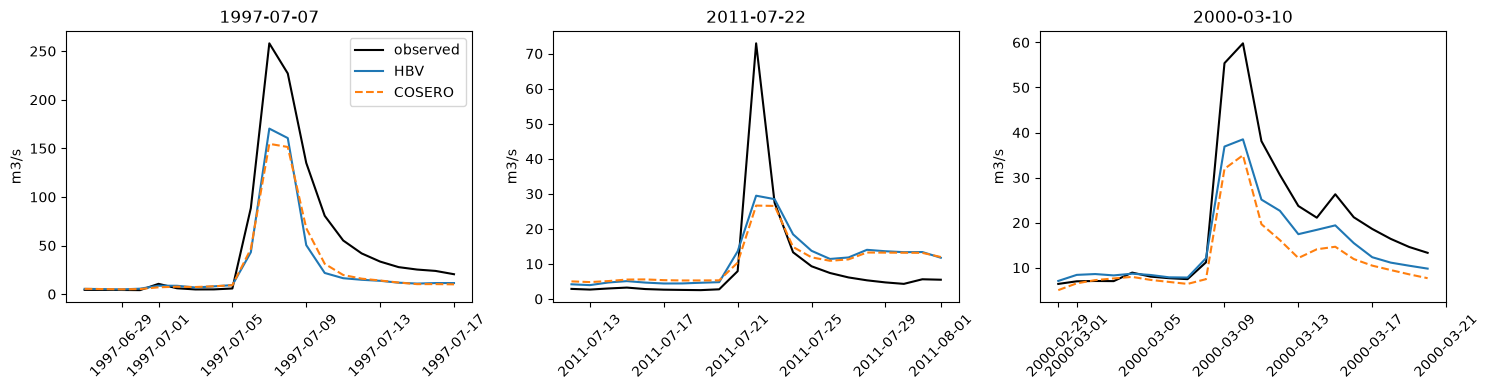

,date,observed_m3s,simulated_m3s,peak_error_%,timing_error_days
0,1997-07-07,258.0,170.3,-34.0,0
1,2011-07-22,72.9,29.4,-59.6,0
2,2000-03-10,59.8,38.5,-35.6,0


In [6]:
q_sim = runs["HBV (DDS)"]
top3 = q_obs.groupby(q_obs.index.year).max().nlargest(3)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
rows = []
for ax, (year, peak_mm) in zip(axes, top3.items()):
    peak_day = q_obs[q_obs.index.year == year].idxmax()
    window = slice(peak_day - pd.DateOffset(days=10), peak_day + pd.DateOffset(days=10))
    ax.plot(q_obs[window] * to_m3s, "k", label="observed")
    ax.plot(q_sim[window] * to_m3s, label="HBV")
    ax.plot(cosero[window] * to_m3s, "--", label="COSERO")
    ax.set(title=str(peak_day.date()), ylabel="m3/s")
    ax.tick_params(axis="x", rotation=45)
    rows.append({"date": peak_day.date(), "observed_m3s": peak_mm * to_m3s,
                 "simulated_m3s": q_sim[window].max() * to_m3s,
                 "peak_error_%": 100 * (q_sim[window].max() / peak_mm - 1),
                 "timing_error_days": (q_sim[window].idxmax() - peak_day).days})
axes[0].legend()
plt.tight_layout()
plt.show()
pd.DataFrame(rows).round(1)

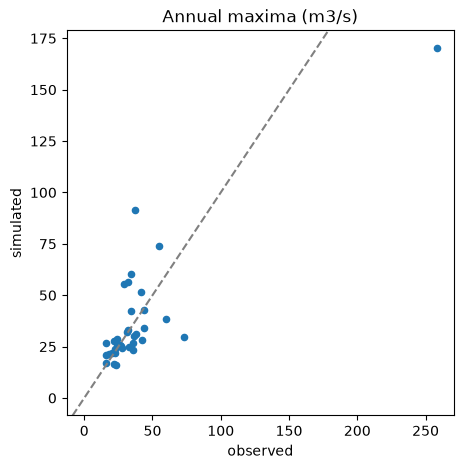

AMS correlation: 0.85


In [7]:
wy = data.index.year + (data.index.month >= 11)          # hydrological year Nov-Oct
ams = pd.DataFrame({"observed": q_obs.groupby(wy).max(),
                    "simulated": q_sim.groupby(wy).max()}).loc[1982:2017] * to_m3s
ax = ams.plot.scatter(x="observed", y="simulated", figsize=(5, 5))
ax.axline((0, 0), slope=1, color="grey", linestyle="--")
ax.set(title="Annual maxima (m3/s)")
plt.show()
print("AMS correlation:", round(ams.corr().iloc[0, 1], 2))

In [8]:
p_year = data["prec"].groupby(wy).sum().loc[1982:2017]
dry_years = p_year.nsmallest(12).index
wet_years = p_year.nlargest(12).index
dry, wet = np.isin(wy, dry_years), np.isin(wy, wet_years)
best_dry, _ = calibrate("dds", data, q_obs, dry, zones, repetitions=5000)
best_wet, _ = calibrate("dds", data, q_obs, wet, zones, repetitions=5000)
dsst = []
for name, params in [("calibrated on dry years", best_dry), ("calibrated on wet years", best_wet)]:
    q = run_hbv(data, params, zones)["q_sim"]
    dsst.append({"model": name, "KGE dry years": kge(q[dry], q_obs[dry]),
                 "KGE wet years": kge(q[wet], q_obs[wet])})
pd.DataFrame(dsst).round(3)

,model,KGE dry years,KGE wet years
0,calibrated on dry years,0.881,0.716
1,calibrated on wet years,0.758,0.836


count    10000.000
mean         0.483
std          0.135
min         -0.566
25%          0.414
50%          0.504
75%          0.575
max          0.785
Name: KGE, dtype: float64
157 behavioural parameter sets


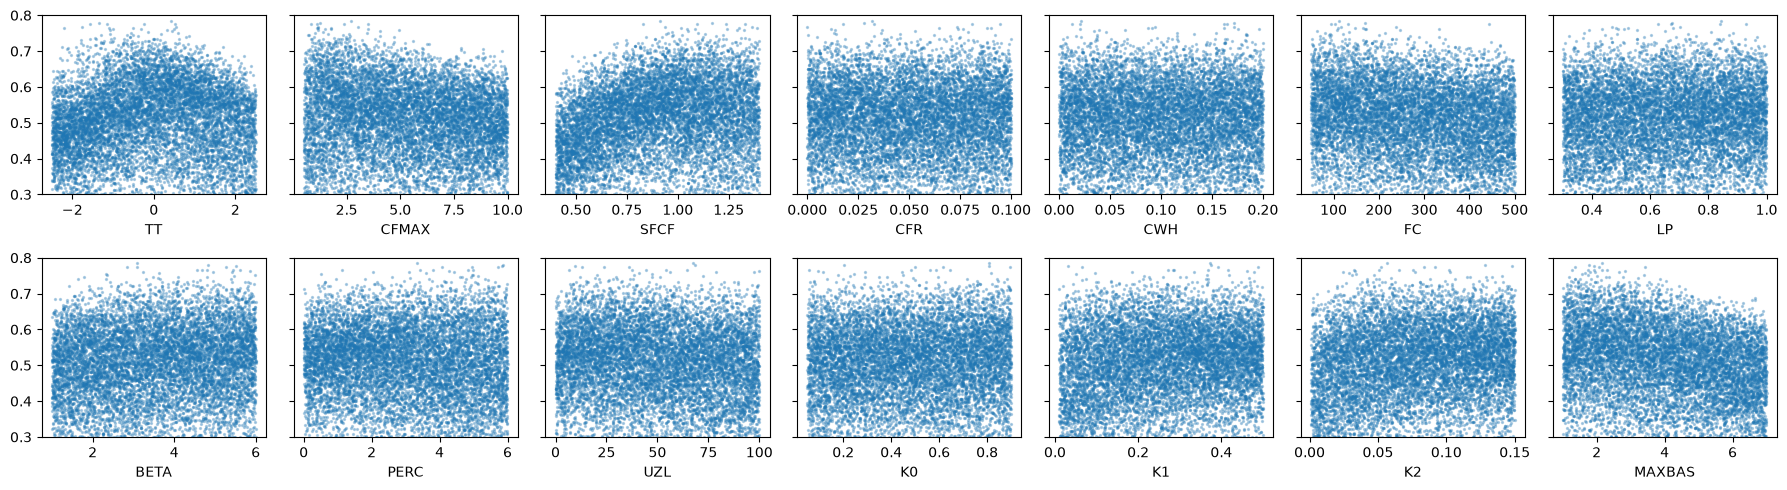

In [9]:
samples = glue_sample(data, q_obs, cal, zones, n=10000)
print(samples["KGE"].describe().round(3))
behavioural = samples[samples["KGE"] >= 0.7]
print(len(behavioural), "behavioural parameter sets")

fig, axes = plt.subplots(2, 7, figsize=(18, 5), sharey=True)
for ax, name in zip(axes.ravel(), PARAM_NAMES):
    ax.scatter(samples[name], samples["KGE"], s=2, alpha=0.3)
    ax.set(xlabel=name, ylim=(0.3, 0.8))
plt.tight_layout()
plt.show()

share of validation days inside the 5-95% band: 0.72


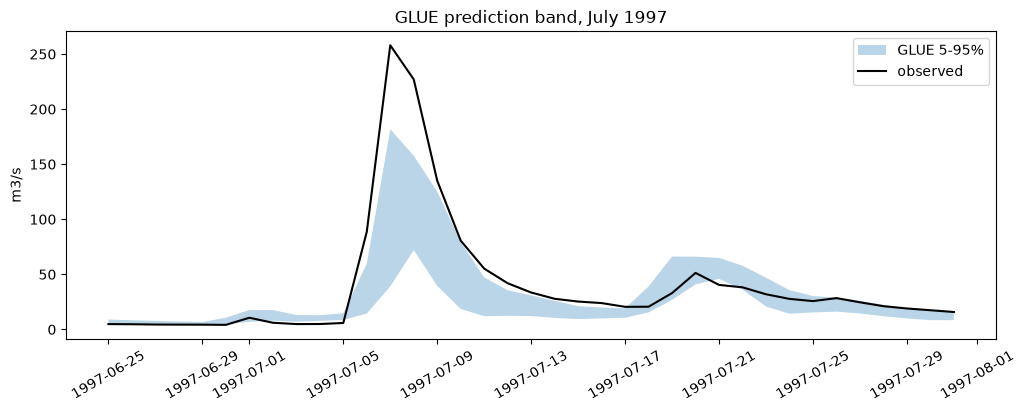

In [10]:
bounds = glue_bounds(data, behavioural, zones)
inside = (q_obs >= bounds["lower"]) & (q_obs <= bounds["upper"])
print("share of validation days inside the 5-95% band:", round(inside[val].mean(), 2))

flood = slice("1997-06-25", "1997-07-31")
fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(bounds.loc[flood].index, bounds.loc[flood, "lower"] * to_m3s,
                bounds.loc[flood, "upper"] * to_m3s, alpha=0.3, label="GLUE 5-95%")
ax.plot(q_obs[flood] * to_m3s, "k", label="observed")
ax.set(ylabel="m3/s", title="GLUE prediction band, July 1997")
ax.tick_params(axis="x", rotation=30)
ax.legend()
plt.show()

In [11]:
with open(RESULTS / "hbv_params_824.json", "w") as f:
    json.dump({"params": best_dds, "zones": zones.tolist()}, f, indent=2)